# Projet de fin de module : Détection des maladies des cultures par CNN

## 1. Contexte

L'agriculture joue un rôle essentiel dans l'économie et la sécurité alimentaire. Cependant, les maladies des cultures peuvent entraîner des pertes importantes lorsqu'elles ne sont pas détectées rapidement.

Ce projet consiste à développer un système intelligent capable d'identifier les maladies des plantes à partir de photographies de feuilles, en utilisant les réseaux de neurones convolutifs (CNN).

## 2. Problématique

Comment concevoir un modèle de Deep Learning capable de reconnaître les maladies des cultures et de conserver de bonnes performances lorsque les images sont prises dans des conditions réelles, notamment avec des variations de luminosité, de fond et de qualité ?

## 3. Objectif général

Développer et évaluer un prototype de classification des maladies des plantes à partir d'images, en étudiant particulièrement sa capacité de généralisation entre un environnement contrôlé et des conditions réelles.

## 4. Jeux de données

- **PlantVillage :** images de feuilles photographiées dans des conditions contrôlées.
- **PlantDoc :** images de plantes photographiées dans des conditions réelles.

## 5. Approche méthodologique

Le projet reposera sur la comparaison d'un modèle MLP et de plusieurs architectures CNN conçues à partir de zéro. Les performances seront évaluées sur les deux jeux de données afin de mesurer la robustesse du modèle.

## 1. Importation des bibliothèques

In [ ]:
# Manipulation des fichiers et dossiers
import os
import random
import zipfile
import shutil

# Manipulation et analyse des données
import numpy as np
import pandas as pd

# Visualisation des données
import matplotlib.pyplot as plt
import seaborn as sns

# Traitement des images
from PIL import Image

# Téléchargement des données
import requests

# Deep Learning avec TensorFlow
import tensorflow as tf

# Séparation et évaluation des données
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support
)

# Afficher les versions
print("NumPy :", np.__version__)
print("Pandas :", pd.__version__)
print("TensorFlow :", tf.__version__)

# Vérifier si un GPU est disponible
print("GPU disponible :", tf.config.list_physical_devices("GPU"))

NumPy : 2.4.6
Pandas : 2.2.3
TensorFlow : 2.21.0
GPU disponible : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


2.Préparer le téléchargement des données

2.1 — Télécharger les deux datasets

In [ ]:
# Créer le dossier principal
os.makedirs("/content/data", exist_ok=True)

# Télécharger PlantDoc
!git clone --depth 1 https://github.com/pratikkayal/PlantDoc-Dataset.git /content/data/PlantDoc

# Télécharger PlantVillage
!git clone --depth 1 https://github.com/spMohanty/PlantVillage-Dataset.git /content/data/PlantVillage_repo

Cloning into '/content/data/PlantDoc'...
remote: Enumerating objects: 2628, done.
remote: Counting objects: 100% (2628/2628), done.
remote: Compressing objects: 100% (2627/2627), done.
remote: Total 2628 (delta 1), reused 2616 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (2628/2628), 932.91 MiB | 35.35 MiB/s, done.
Resolving deltas: 100% (1/1), done.
Updating files: 100% (2581/2581), done.
Cloning into '/content/data/PlantVillage_repo'...
remote: Enumerating objects: 163219, done.
remote: Counting objects: 100% (163219/163219), done.
remote: Compressing objects: 100% (163125/163125), done.
remote: Total 163219 (delta 93), reused 163215 (delta 93), pack-reused 0 (from 0)
Receiving objects: 100% (163219/163219), 2.00 GiB | 16.30 MiB/s, done.
Resolving deltas: 100% (93/93), done.
Updating files: 100% (182404/182404), done.


2.2 — Examiner les classes des deux datasets

In [ ]:
import os

# Chemins des datasets
PLANTDOC_DIR = "/content/data/PlantDoc"
PLANTVILLAGE_DIR = "/content/data/PlantVillage_repo/raw/color"

# Vérifier PlantDoc
print("Dossiers PlantDoc :", os.listdir(PLANTDOC_DIR))

print("\nClasses dans PlantDoc/train :")
print(os.listdir(os.path.join(PLANTDOC_DIR, "train")))

# Vérifier les classes de tomate dans PlantVillage
classes_tomate = [
    d for d in os.listdir(PLANTVILLAGE_DIR)
    if "Tomato" in d
]

print("\nNombre de classes de tomate dans PlantVillage :", len(classes_tomate))

for classe in sorted(classes_tomate):
    print("-", classe)

Dossiers PlantDoc : ['README.md', 'train', '.git', 'PlantDoc_Examples.png', 'test', 'LICENSE.txt']

Classes dans PlantDoc/train :
['Corn Gray leaf spot', 'Squash Powdery mildew leaf', 'Blueberry leaf', 'Raspberry leaf', 'Corn leaf blight', 'Apple Scab Leaf', 'grape leaf black rot', 'Bell_pepper leaf spot', 'Tomato mold leaf', 'Tomato leaf', 'Bell_pepper leaf', 'Tomato Early blight leaf', 'Corn rust leaf', 'Tomato leaf late blight', 'Tomato leaf yellow virus', 'grape leaf', 'Tomato leaf bacterial spot', 'Tomato Septoria leaf spot', 'Potato leaf late blight', 'Apple leaf', 'Cherry leaf', 'Strawberry leaf', 'Peach leaf', 'Tomato two spotted spider mites leaf', 'Apple rust leaf', 'Soyabean leaf', 'Tomato leaf mosaic virus', 'Potato leaf early blight']

Nombre de classes de tomate dans PlantVillage : 10
- Tomato___Bacterial_spot
- Tomato___Early_blight
- Tomato___Late_blight
- Tomato___Leaf_Mold
- Tomato___Septoria_leaf_spot
- Tomato___Spider_mites Two-spotted_spider_mite
- Tomato___Target_

2.3 — Analyse de la répartition des images par classe

In [ ]:
import os
import pandas as pd

# Fonction pour compter les images dans chaque classe
def compter_images(dossier):
    extensions = (".jpg", ".jpeg", ".png", ".bmp")
    effectifs = {}

    for classe in sorted(os.listdir(dossier)):
        chemin_classe = os.path.join(dossier, classe)

        if os.path.isdir(chemin_classe):
            images = [
                f for f in os.listdir(chemin_classe)
                if f.lower().endswith(extensions)
            ]
            effectifs[classe] = len(images)

    return effectifs


# Effectifs PlantDoc
pv_effectifs = compter_images(PLANTVILLAGE_DIR)
pd_train_effectifs = compter_images(os.path.join(PLANTDOC_DIR, "train"))
pd_test_effectifs = compter_images(os.path.join(PLANTDOC_DIR, "test"))

# Afficher les résultats
print("PLANTVILLAGE")
display(pd.DataFrame(
    pv_effectifs.items(),
    columns=["Classe", "Nombre d'images"]
))

print("\nPLANTDOC - TRAIN")
display(pd.DataFrame(
    pd_train_effectifs.items(),
    columns=["Classe", "Nombre d'images"]
))

print("\nPLANTDOC - TEST")
display(pd.DataFrame(
    pd_test_effectifs.items(),
    columns=["Classe", "Nombre d'images"]
))

PLANTVILLAGE


,Classe,Nombre d'images
0,Apple___Apple_scab,630
1,Apple___Black_rot,621
2,Apple___Cedar_apple_rust,275
3,Apple___healthy,1645
4,Blueberry___healthy,1502
5,Cherry_(including_sour)___Powdery_mildew,1052
6,Cherry_(including_sour)___healthy,854
7,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,513
8,Corn_(maize)___Common_rust_,1192
9,Corn_(maize)___Northern_Leaf_Blight,985



PLANTDOC - TRAIN


,Classe,Nombre d'images
0,Apple Scab Leaf,83
1,Apple leaf,82
2,Apple rust leaf,79
3,Bell_pepper leaf,53
4,Bell_pepper leaf spot,62
5,Blueberry leaf,106
6,Cherry leaf,47
7,Corn Gray leaf spot,64
8,Corn leaf blight,180
9,Corn rust leaf,106



PLANTDOC - TEST


,Classe,Nombre d'images
0,Apple Scab Leaf,10
1,Apple leaf,9
2,Apple rust leaf,10
3,Bell_pepper leaf,8
4,Bell_pepper leaf spot,9
5,Blueberry leaf,11
6,Cherry leaf,10
7,Corn Gray leaf spot,4
8,Corn leaf blight,12
9,Corn rust leaf,10


2.4 — Visualisation des images des deux datasets

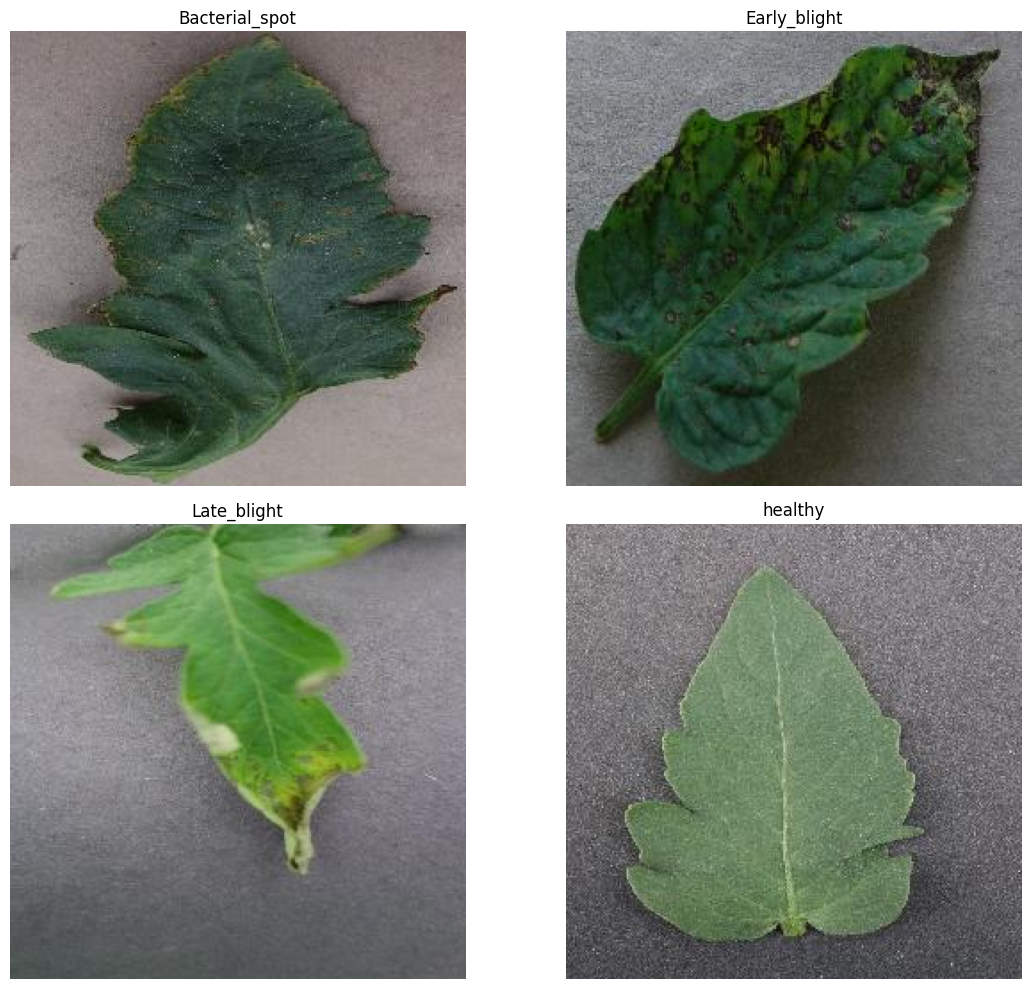

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import os
import random

# Quelques classes de tomate à visualiser
classes_a_visualiser = [
    "Tomato___Bacterial_spot",
    "Tomato___Early_blight",
    "Tomato___Late_blight",
    "Tomato___healthy"
]

plt.figure(figsize=(12, 10))

for i, classe in enumerate(classes_a_visualiser):
    dossier = os.path.join(PLANTVILLAGE_DIR, classe)
    image_nom = random.choice(os.listdir(dossier))
    image = Image.open(os.path.join(dossier, image_nom))

    plt.subplot(2, 2, i + 1)
    plt.imshow(image)
    plt.title(classe.replace("Tomato___", ""))
    plt.axis("off")

plt.tight_layout()
plt.show()

2.5 Visualisation des images PlantDoc

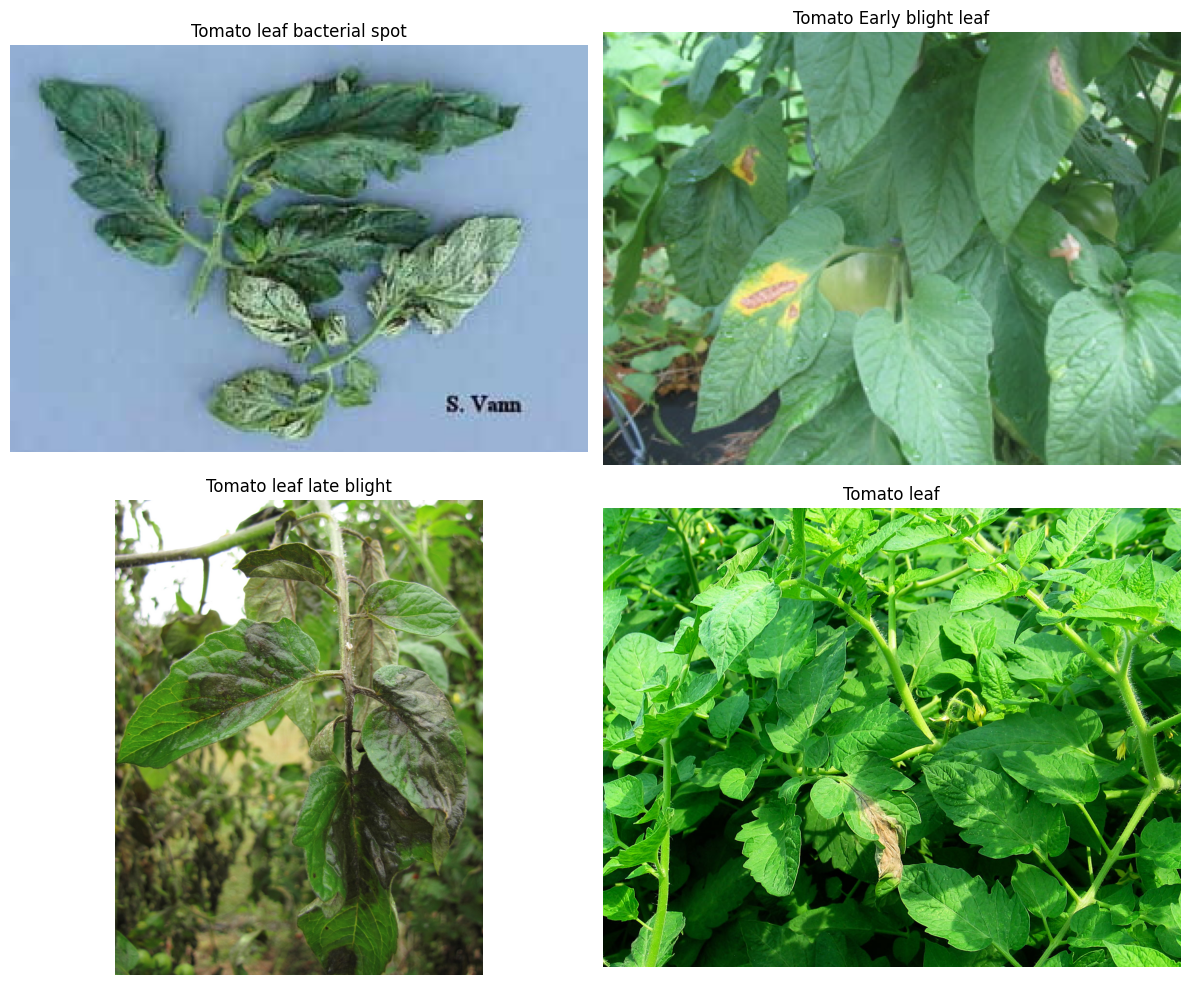

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import os
import random

classes_plantdoc = [
    "Tomato leaf bacterial spot",
    "Tomato Early blight leaf",
    "Tomato leaf late blight",
    "Tomato leaf"
]

plt.figure(figsize=(12, 10))

for i, classe in enumerate(classes_plantdoc):
    dossier = os.path.join(PLANTDOC_DIR, "train", classe)

    images = [
        f for f in os.listdir(dossier)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    image_nom = random.choice(images)
    image = Image.open(os.path.join(dossier, image_nom)).convert("RGB")

    plt.subplot(2, 2, i + 1)
    plt.imshow(image)
    plt.title(classe)
    plt.axis("off")

plt.tight_layout()
plt.show()

3 — Préparation des données et harmonisation des classes

In [ ]:
# Correspondance entre les classes PlantVillage et PlantDoc

correspondance_classes = {
    "Bacterial_spot": {
        "plantvillage": "Tomato___Bacterial_spot",
        "plantdoc": "Tomato leaf bacterial spot"
    },
    "Early_blight": {
        "plantvillage": "Tomato___Early_blight",
        "plantdoc": "Tomato Early blight leaf"
    },
    "Late_blight": {
        "plantvillage": "Tomato___Late_blight",
        "plantdoc": "Tomato leaf late blight"
    },
    "Leaf_Mold": {
        "plantvillage": "Tomato___Leaf_Mold",
        "plantdoc": "Tomato mold leaf"
    },
    "Septoria_leaf_spot": {
        "plantvillage": "Tomato___Septoria_leaf_spot",
        "plantdoc": "Tomato Septoria leaf spot"
    },
    "Spider_mites": {
        "plantvillage": "Tomato___Spider_mites Two-spotted_spider_mite",
        "plantdoc": "Tomato two spotted spider mites leaf"
    },
    "Tomato_mosaic_virus": {
        "plantvillage": "Tomato___Tomato_mosaic_virus",
        "plantdoc": "Tomato leaf mosaic virus"
    },
    "Yellow_Leaf_Curl_Virus": {
        "plantvillage": "Tomato___Tomato_Yellow_Leaf_Curl_Virus",
        "plantdoc": "Tomato leaf yellow virus"
    }
}

print("Nombre de classes communes :", len(correspondance_classes))

for nom, sources in correspondance_classes.items():
    print(nom, ":", sources)

Nombre de classes communes : 8
Bacterial_spot : {'plantvillage': 'Tomato___Bacterial_spot', 'plantdoc': 'Tomato leaf bacterial spot'}
Early_blight : {'plantvillage': 'Tomato___Early_blight', 'plantdoc': 'Tomato Early blight leaf'}
Late_blight : {'plantvillage': 'Tomato___Late_blight', 'plantdoc': 'Tomato leaf late blight'}
Leaf_Mold : {'plantvillage': 'Tomato___Leaf_Mold', 'plantdoc': 'Tomato mold leaf'}
Septoria_leaf_spot : {'plantvillage': 'Tomato___Septoria_leaf_spot', 'plantdoc': 'Tomato Septoria leaf spot'}
Spider_mites : {'plantvillage': 'Tomato___Spider_mites Two-spotted_spider_mite', 'plantdoc': 'Tomato two spotted spider mites leaf'}
Tomato_mosaic_virus : {'plantvillage': 'Tomato___Tomato_mosaic_virus', 'plantdoc': 'Tomato leaf mosaic virus'}
Yellow_Leaf_Curl_Virus : {'plantvillage': 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'plantdoc': 'Tomato leaf yellow virus'}


3.1 — Création des index des images

In [ ]:
import os
import pandas as pd

extensions = (".jpg", ".jpeg", ".png", ".bmp")

# Fonction pour construire un index d'images
def creer_index(dossier, correspondance, source):

    donnees = []

    for classe_commune, noms in correspondance.items():

        nom_dossier = noms[source]
        chemin_classe = os.path.join(dossier, nom_dossier)

        if not os.path.isdir(chemin_classe):
            print("Dossier absent :", chemin_classe)
            continue

        for fichier in os.listdir(chemin_classe):

            if fichier.lower().endswith(extensions):

                donnees.append({
                    "chemin": os.path.join(chemin_classe, fichier),
                    "classe": classe_commune
                })

    return pd.DataFrame(donnees)


# Construire les deux index
df_plantvillage = creer_index(
    PLANTVILLAGE_DIR,
    correspondance_classes,
    "plantvillage"
)

df_plantdoc_train = creer_index(
    os.path.join(PLANTDOC_DIR, "train"),
    correspondance_classes,
    "plantdoc"
)

df_plantdoc_test = creer_index(
    os.path.join(PLANTDOC_DIR, "test"),
    correspondance_classes,
    "plantdoc"
)

# Afficher les résultats
print("PlantVillage :", len(df_plantvillage), "images")
print("PlantDoc train :", len(df_plantdoc_train), "images")
print("PlantDoc test :", len(df_plantdoc_test), "images")

print("\nRépartition PlantVillage :")
display(df_plantvillage["classe"].value_counts().sort_index())

print("\nRépartition PlantDoc train :")
display(df_plantdoc_train["classe"].value_counts().sort_index())

print("\nRépartition PlantDoc test :")
display(df_plantdoc_test["classe"].value_counts().sort_index())

Dossier absent : /content/data/PlantDoc/test/Tomato two spotted spider mites leaf
PlantVillage : 15165 images
PlantDoc train : 622 images
PlantDoc test : 61 images

Répartition PlantVillage :


,count
classe,
Bacterial_spot,2127
Early_blight,1000
Late_blight,1909
Leaf_Mold,952
Septoria_leaf_spot,1771
Spider_mites,1676
Tomato_mosaic_virus,373
Yellow_Leaf_Curl_Virus,5357



Répartition PlantDoc train :


,count
classe,
Bacterial_spot,101
Early_blight,79
Late_blight,101
Leaf_Mold,85
Septoria_leaf_spot,140
Spider_mites,2
Tomato_mosaic_virus,44
Yellow_Leaf_Curl_Virus,70



Répartition PlantDoc test :


,count
classe,
Bacterial_spot,9
Early_blight,9
Late_blight,10
Leaf_Mold,6
Septoria_leaf_spot,11
Tomato_mosaic_virus,10
Yellow_Leaf_Curl_Virus,6


3.2 — Préparer les données d'entraînement et de validation

In [ ]:
from sklearn.model_selection import train_test_split

# Les 7 classes retenues
classes_finales = [
    "Bacterial_spot",
    "Early_blight",
    "Late_blight",
    "Leaf_Mold",
    "Septoria_leaf_spot",
    "Tomato_mosaic_virus",
    "Yellow_Leaf_Curl_Virus"
]

# Garder uniquement les 7 classes
df_pv = df_plantvillage[
    df_plantvillage["classe"].isin(classes_finales)
].copy()

df_pd_train = df_plantdoc_train[
    df_plantdoc_train["classe"].isin(classes_finales)
].copy()

df_pd_test = df_plantdoc_test[
    df_plantdoc_test["classe"].isin(classes_finales)
].copy()

# Séparation PlantVillage : 70 % train et 30 % temporaire
df_train, df_temp = train_test_split(
    df_pv,
    test_size=0.30,
    random_state=42,
    stratify=df_pv["classe"]
)

# Séparation du temporaire : 15 % validation et 15 % test
df_val, df_test = train_test_split(
    df_temp,
    test_size=0.50,
    random_state=42,
    stratify=df_temp["classe"]
)

# Afficher les dimensions
print("PlantVillage - Train :", len(df_train))
print("PlantVillage - Validation :", len(df_val))
print("PlantVillage - Test :", len(df_test))
print("PlantDoc - Train :", len(df_pd_train))
print("PlantDoc - Test :", len(df_pd_test))

print("\nRépartition des classes dans PlantVillage - Train :")
display(df_train["classe"].value_counts().sort_index())

PlantVillage - Train : 9442
PlantVillage - Validation : 2023
PlantVillage - Test : 2024
PlantDoc - Train : 620
PlantDoc - Test : 61

Répartition des classes dans PlantVillage - Train :


,count
classe,
Bacterial_spot,1489
Early_blight,700
Late_blight,1336
Leaf_Mold,666
Septoria_leaf_spot,1240
Tomato_mosaic_virus,261
Yellow_Leaf_Curl_Virus,3750


3.3 — Prétraitement et chargement des images

In [ ]:
# Taille des images et paramètres
IMG_SIZE = (128, 128)
BATCH_SIZE = 32

# Associer chaque classe à un numéro
class_names = sorted(classes_finales)

class_to_index = {
    classe: index
    for index, classe in enumerate(class_names)
}

print("Correspondance des classes :")
print(class_to_index)


# Fonction de préparation d'un dataset TensorFlow
def preparer_dataset(df, entrainement=False):

    chemins = df["chemin"].values

    etiquettes = df["classe"].map(class_to_index).values

    dataset = tf.data.Dataset.from_tensor_slices(
        (chemins, etiquettes)
    )

    # Charger et transformer les images
    def charger_image(chemin, etiquette):

        image = tf.io.read_file(chemin)

        image = tf.io.decode_image(
            image,
            channels=3,
            expand_animations=False
        )

        image.set_shape([None, None, 3])

        image = tf.image.resize(image, IMG_SIZE)

        image = tf.cast(image, tf.float32) / 255.0

        return image, etiquette

    dataset = dataset.map(
        charger_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    # Mélanger uniquement les données d'entraînement
    if entrainement:
        dataset = dataset.shuffle(
            buffer_size=1000,
            seed=42
        )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


# Préparer les quatre ensembles
train_ds = preparer_dataset(df_train, entrainement=True)
val_ds = preparer_dataset(df_val)
test_ds = preparer_dataset(df_test)
plantdoc_test_ds = preparer_dataset(df_pd_test)

print("\nPréparation terminée.")

Correspondance des classes :
{'Bacterial_spot': 0, 'Early_blight': 1, 'Late_blight': 2, 'Leaf_Mold': 3, 'Septoria_leaf_spot': 4, 'Tomato_mosaic_virus': 5, 'Yellow_Leaf_Curl_Virus': 6}

Préparation terminée.


3.4 — Vérification des données

Dimensions des images : (32, 128, 128, 3)
Dimensions des étiquettes : (32,)
Valeur minimale : 0.0
Valeur maximale : 0.97843134


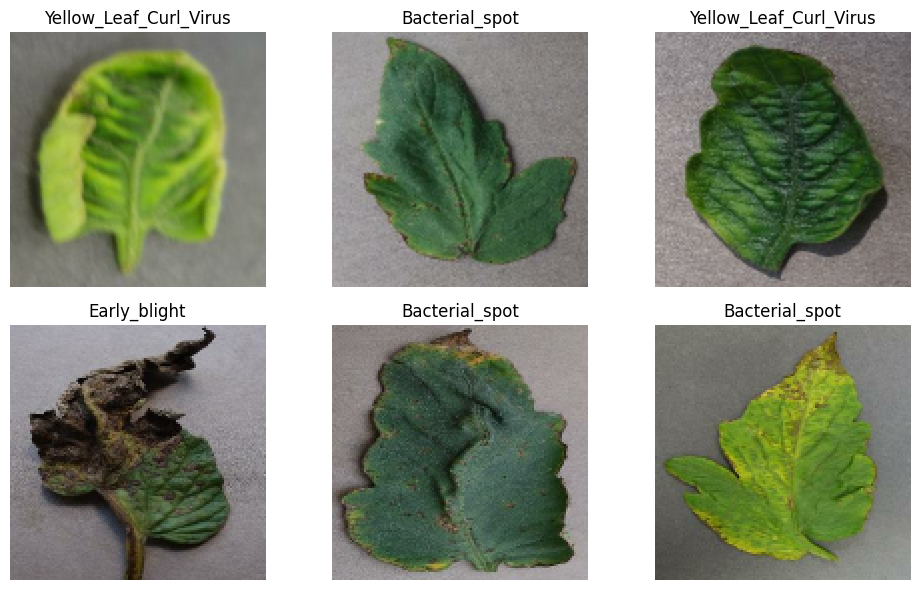

In [ ]:
# Récupérer un premier batch d'images
images, etiquettes = next(iter(train_ds))

# Afficher les dimensions
print("Dimensions des images :", images.shape)
print("Dimensions des étiquettes :", etiquettes.shape)

# Afficher les valeurs des pixels
print("Valeur minimale :", tf.reduce_min(images).numpy())
print("Valeur maximale :", tf.reduce_max(images).numpy())

# Afficher quelques images avec leurs classes
plt.figure(figsize=(10, 6))

for i in range(6):
    plt.subplot(2, 3, i + 1)

    plt.imshow(images[i].numpy())

    classe = class_names[etiquettes[i].numpy()]
    plt.title(classe)

    plt.axis("off")

plt.tight_layout()
plt.show()

3.4.1 — Construction du MLP (baseline)

In [ ]:
from tensorflow.keras import layers, models

mlp_model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    # Aplatir l'image en un vecteur
    layers.Flatten(),

    # Couche entièrement connectée
    layers.Dense(128, activation="relu"),

    # Réduction du surapprentissage
    layers.Dropout(0.5),

    # Classification des 7 maladies
    layers.Dense(7, activation="softmax")
])

mlp_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

mlp_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 49152)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     6,291,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,292,487 (24.00 MB)

 Trainable params: 6,292,487 (24.00 MB)

 Non-trainable params: 0 (0.00 B)

3.4.2 – Entraînement du MLP

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop_mlp = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history_mlp = mlp_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    callbacks=[early_stop_mlp]
)

Epoch 1/8
296/296 ━━━━━━━━━━━━━━━━━━━━ 8s 23ms/step - accuracy: 0.4030 - loss: 1.6833 - val_accuracy: 0.4103 - val_loss: 1.6655
Epoch 2/8
296/296 ━━━━━━━━━━━━━━━━━━━━ 9s 29ms/step - accuracy: 0.4035 - loss: 1.6759 - val_accuracy: 0.4078 - val_loss: 1.6669
Epoch 3/8
296/296 ━━━━━━━━━━━━━━━━━━━━ 10s 29ms/step - accuracy: 0.4021 - loss: 1.6743 - val_accuracy: 0.4103 - val_loss: 1.6575
Epoch 4/8
296/296 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step - accuracy: 0.4017 - loss: 1.6735 - val_accuracy: 0.4103 - val_loss: 1.6561
Epoch 5/8
296/296 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step - accuracy: 0.4017 - loss: 1.6727 - val_accuracy: 0.4103 - val_loss: 1.6555
Epoch 6/8
296/296 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.4028 - loss: 1.6701 - val_accuracy: 0.4108 - val_loss: 1.6551
Epoch 7/8
296/296 ━━━━━━━━━━━━━━━━━━━━ 7s 23ms/step - accuracy: 0.4010 - loss: 1.6735 - val_accuracy: 0.4108 - val_loss: 1.6549
Epoch 8/8
296/296 ━━━━━━━━━━━━━━━━━━━━ 11s 24ms/step - accuracy: 0.4024 - loss: 1.6706 - val_accuracy:

3.4.3 – Évaluation du MLP sur le jeu de test

In [ ]:
loss_mlp, acc_mlp = mlp_model.evaluate(test_ds)

print("Résultats du MLP sur PlantVillage")
print("Loss :", round(loss_mlp, 4))
print("Accuracy :", round(acc_mlp * 100, 2), "%")

64/64 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step - accuracy: 0.4091 - loss: 1.6576
Résultats du MLP sur PlantVillage
Loss : 1.6576
Accuracy : 40.91 %


3.4.4 – Rapport de classification du MLP

In [ ]:
from sklearn.metrics import classification_report
import numpy as np

# Récupérer les vraies étiquettes
y_true_mlp = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

# Obtenir les prédictions du MLP
y_pred_mlp = np.argmax(
    mlp_model.predict(test_ds),
    axis=1
)

# Afficher le rapport de classification
print(classification_report(
    y_true_mlp,
    y_pred_mlp,
    target_names=class_names,
    zero_division=0
))

64/64 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step
                        precision    recall  f1-score   support

        Bacterial_spot       0.00      0.00      0.00       319
          Early_blight       0.00      0.00      0.00       150
           Late_blight       1.00      0.08      0.15       287
             Leaf_Mold       0.00      0.00      0.00       143
    Septoria_leaf_spot       0.00      0.00      0.00       265
   Tomato_mosaic_virus       0.00      0.00      0.00        56
Yellow_Leaf_Curl_Virus       0.40      1.00      0.57       804

              accuracy                           0.41      2024
             macro avg       0.20      0.15      0.10      2024
          weighted avg       0.30      0.41      0.25      2024



3.5 — Construction de l'architecture CNN 1

In [ ]:
from tensorflow.keras import layers, models

# Construction du CNN
cnn_model = models.Sequential([

    # Image d'entrée
    layers.Input(shape=(128, 128, 3)),

    # Première couche convolutionnelle
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Deuxième couche convolutionnelle
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Classification
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    # Couche de sortie
    layers.Dense(7, activation="softmax")
])

# Configuration de l'apprentissage
cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Afficher l'architecture
cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     7,372,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,393,223 (28.20 MB)

 Trainable params: 7,393,223 (28.20 MB)

 Non-trainable params: 0 (0.00 B)

3.6 — Entraînement du CNN 1

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Arrêter si la perte de validation ne s'améliore plus
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

# Sauvegarder le meilleur modèle
checkpoint = ModelCheckpoint(
    "/content/best_cnn1.keras",
    monitor="val_loss",
    save_best_only=True
)

# Entraînement
history_cnn1 = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[early_stop, checkpoint]
)

Epoch 1/10
296/296 ━━━━━━━━━━━━━━━━━━━━ 27s 58ms/step - accuracy: 0.6959 - loss: 0.8755 - val_accuracy: 0.8141 - val_loss: 0.5080
Epoch 2/10
296/296 ━━━━━━━━━━━━━━━━━━━━ 25s 30ms/step - accuracy: 0.8218 - loss: 0.5091 - val_accuracy: 0.8463 - val_loss: 0.4456
Epoch 3/10
296/296 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - accuracy: 0.8631 - loss: 0.3943 - val_accuracy: 0.8695 - val_loss: 0.3626
Epoch 4/10
296/296 ━━━━━━━━━━━━━━━━━━━━ 9s 29ms/step - accuracy: 0.8868 - loss: 0.3171 - val_accuracy: 0.8804 - val_loss: 0.3402
Epoch 5/10
296/296 ━━━━━━━━━━━━━━━━━━━━ 9s 25ms/step - accuracy: 0.9047 - loss: 0.2771 - val_accuracy: 0.8917 - val_loss: 0.3162
Epoch 6/10
296/296 ━━━━━━━━━━━━━━━━━━━━ 9s 30ms/step - accuracy: 0.9239 - loss: 0.2148 - val_accuracy: 0.9105 - val_loss: 0.2633
Epoch 7/10
296/296 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - accuracy: 0.9327 - loss: 0.1824 - val_accuracy: 0.8972 - val_loss: 0.3255
Epoch 8/10
296/296 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step - accuracy: 0.9373 - loss: 0.1757 - val_

3.7 — Visualisation des courbes d'apprentissage

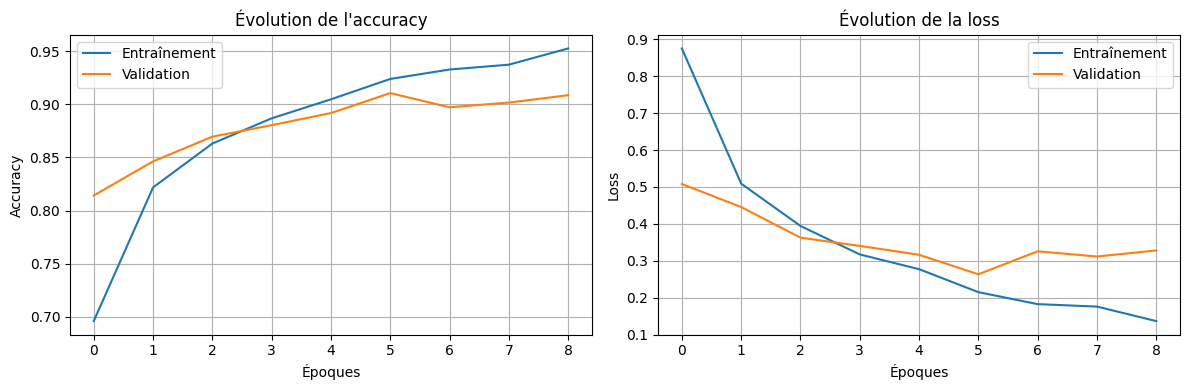

In [ ]:
# Récupérer les résultats de l'entraînement
historique = history_cnn1.history

# Créer deux graphiques
plt.figure(figsize=(12, 4))

# Courbe de l'accuracy
plt.subplot(1, 2, 1)
plt.plot(historique["accuracy"], label="Entraînement")
plt.plot(historique["val_accuracy"], label="Validation")
plt.title("Évolution de l'accuracy")
plt.xlabel("Époques")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()

# Courbe de la loss
plt.subplot(1, 2, 2)
plt.plot(historique["loss"], label="Entraînement")
plt.plot(historique["val_loss"], label="Validation")
plt.title("Évolution de la loss")
plt.xlabel("Époques")
plt.ylabel("Loss")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

3.8 — Évaluation du CNN 1 sur PlantVillage (test)

In [ ]:
# Évaluation sur le test PlantVillage
loss_test, accuracy_test = cnn_model.evaluate(test_ds)

print("Résultats sur PlantVillage (test)")
print("Loss :", round(loss_test, 4))
print("Accuracy :", round(accuracy_test * 100, 2), "%")

64/64 ━━━━━━━━━━━━━━━━━━━━ 4s 63ms/step - accuracy: 0.9071 - loss: 0.2600
Résultats sur PlantVillage (test)
Loss : 0.26
Accuracy : 90.71 %


3.9 — Rapport de classification : précision, rappel et F1-score

In [ ]:
# Prédictions du modèle sur les données de test
y_pred = np.argmax(cnn_model.predict(test_ds), axis=1)

# Récupération des vraies étiquettes
y_true = np.concatenate([
    etiquettes.numpy() for images, etiquettes in test_ds
])

# Rapport de classification
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    zero_division=0
))

64/64 ━━━━━━━━━━━━━━━━━━━━ 3s 35ms/step
                        precision    recall  f1-score   support

        Bacterial_spot       0.93      0.96      0.94       319
          Early_blight       0.76      0.77      0.76       150
           Late_blight       0.88      0.79      0.83       287
             Leaf_Mold       0.86      0.77      0.81       143
    Septoria_leaf_spot       0.79      0.92      0.85       265
   Tomato_mosaic_virus       0.91      0.89      0.90        56
Yellow_Leaf_Curl_Virus       0.99      0.98      0.98       804

              accuracy                           0.91      2024
             macro avg       0.87      0.87      0.87      2024
          weighted avg       0.91      0.91      0.91      2024



3.10 — Matrice de confusion

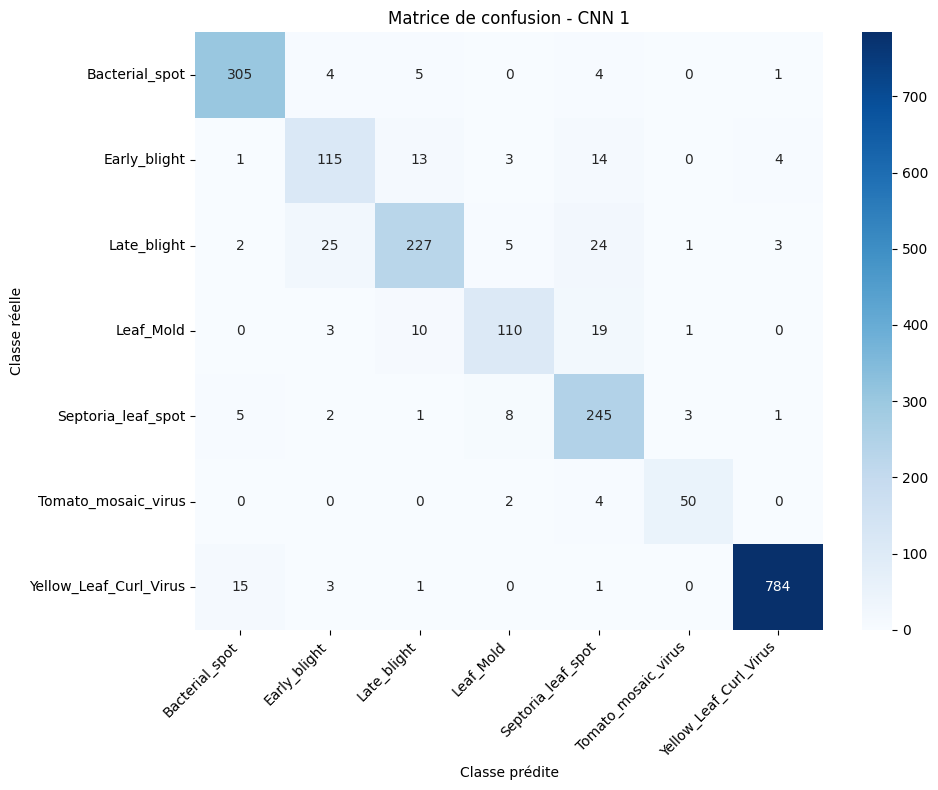

In [ ]:
# Calcul de la matrice de confusion
cm = confusion_matrix(y_true, y_pred)

# Affichage
plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Matrice de confusion - CNN 1")
plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
# Afficher la matrice de confusion sous forme de tableau
matrice_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)

print(matrice_df)

                        Bacterial_spot  Early_blight  Late_blight  Leaf_Mold  \
Bacterial_spot                     305             4            5          0   
Early_blight                         1           115           13          3   
Late_blight                          2            25          227          5   
Leaf_Mold                            0             3           10        110   
Septoria_leaf_spot                   5             2            1          8   
Tomato_mosaic_virus                  0             0            0          2   
Yellow_Leaf_Curl_Virus              15             3            1          0   

                        Septoria_leaf_spot  Tomato_mosaic_virus  \
Bacterial_spot                           4                    0   
Early_blight                            14                    0   
Late_blight                             24                    1   
Leaf_Mold                               19                    1   
Septoria_leaf_spot      

3.11 — Évaluation de la robustesse sur PlantDoc

In [ ]:
# Évaluation du CNN 1 sur PlantDoc
loss_plantdoc, accuracy_plantdoc = cnn_model.evaluate(plantdoc_test_ds)

print("Résultats sur PlantDoc")
print("Loss :", round(loss_plantdoc, 4))
print("Accuracy :", round(accuracy_plantdoc * 100, 2), "%")

# Prédictions
y_pred_plantdoc = np.argmax(
    cnn_model.predict(plantdoc_test_ds),
    axis=1
)

# Vraies étiquettes
y_true_plantdoc = np.concatenate([
    etiquettes.numpy()
    for images, etiquettes in plantdoc_test_ds
])

# Rapport de classification
print("\nRapport de classification sur PlantDoc :")
print(classification_report(
    y_true_plantdoc,
    y_pred_plantdoc,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 2s/step - accuracy: 0.2131 - loss: 16.8472
Résultats sur PlantDoc
Loss : 16.8472
Accuracy : 21.31 %
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 577ms/step

Rapport de classification sur PlantDoc :
                        precision    recall  f1-score   support

        Bacterial_spot       0.00      0.00      0.00         9
          Early_blight       0.23      0.33      0.27         9
           Late_blight       0.21      0.80      0.33        10
             Leaf_Mold       0.33      0.17      0.22         6
    Septoria_leaf_spot       0.33      0.09      0.14        11
   Tomato_mosaic_virus       0.00      0.00      0.00        10
Yellow_Leaf_Curl_Virus       0.00      0.00      0.00         6

              accuracy                           0.21        61
             macro avg       0.16      0.20      0.14        61
          weighted avg       0.16      0.21      0.14        61



3.12 — Matrice de confusion sur PlantDoc

In [ ]:
cm_plantdoc = confusion_matrix(
    y_true_plantdoc,
    y_pred_plantdoc,
    labels=list(range(len(class_names)))
)

matrice_plantdoc = pd.DataFrame(
    cm_plantdoc,
    index=class_names,
    columns=class_names
)

print(matrice_plantdoc)

                        Bacterial_spot  Early_blight  Late_blight  Leaf_Mold  \
Bacterial_spot                       0             1            6          1   
Early_blight                         0             3            6          0   
Late_blight                          0             1            8          1   
Leaf_Mold                            0             1            1          1   
Septoria_leaf_spot                   1             2            7          0   
Tomato_mosaic_virus                  0             3            7          0   
Yellow_Leaf_Curl_Virus               0             2            3          0   

                        Septoria_leaf_spot  Tomato_mosaic_virus  \
Bacterial_spot                           0                    0   
Early_blight                             0                    0   
Late_blight                              0                    0   
Leaf_Mold                                1                    0   
Septoria_leaf_spot      

3.13 Construction du CNN 2 avec data augmentation

In [ ]:
from tensorflow.keras import layers, models

# Data augmentation
augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.10),
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.10)
], name="data_augmentation")

# Architecture du CNN 2
cnn_model2 = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    augmentation,

    layers.Conv2D(32, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),

    layers.Dense(len(class_names), activation="softmax")
])

cnn_model2.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_model2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,335 (434.90 KB)

 Trainable params: 110,887 (433.15 KB)

 Non-trainable params: 448 (1.75 KB)

3.14 — Entraînement du CNN 2

In [ ]:
# Arrêt anticipé si la validation ne s'améliore plus
early_stop2 = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

# Sauvegarder le meilleur modèle
checkpoint2 = ModelCheckpoint(
    "/content/best_cnn2.keras",
    monitor="val_loss",
    save_best_only=True
)

# Entraînement du CNN 2
history_cnn2 = cnn_model2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[early_stop2, checkpoint2]
)

Epoch 1/10
296/296 ━━━━━━━━━━━━━━━━━━━━ 25s 50ms/step - accuracy: 0.7211 - loss: 0.8048 - val_accuracy: 0.2071 - val_loss: 3.4089
Epoch 2/10
296/296 ━━━━━━━━━━━━━━━━━━━━ 15s 49ms/step - accuracy: 0.8174 - loss: 0.5259 - val_accuracy: 0.5714 - val_loss: 1.2496
Epoch 3/10
296/296 ━━━━━━━━━━━━━━━━━━━━ 15s 49ms/step - accuracy: 0.8502 - loss: 0.4297 - val_accuracy: 0.6831 - val_loss: 1.1848
Epoch 4/10
296/296 ━━━━━━━━━━━━━━━━━━━━ 15s 50ms/step - accuracy: 0.8650 - loss: 0.3811 - val_accuracy: 0.8285 - val_loss: 0.4775
Epoch 5/10
296/296 ━━━━━━━━━━━━━━━━━━━━ 20s 49ms/step - accuracy: 0.8848 - loss: 0.3348 - val_accuracy: 0.5368 - val_loss: 1.6938
Epoch 6/10
296/296 ━━━━━━━━━━━━━━━━━━━━ 16s 50ms/step - accuracy: 0.8994 - loss: 0.2959 - val_accuracy: 0.7647 - val_loss: 0.6856
Epoch 7/10
296/296 ━━━━━━━━━━━━━━━━━━━━ 17s 56ms/step - accuracy: 0.8957 - loss: 0.3011 - val_accuracy: 0.8482 - val_loss: 0.3703
Epoch 8/10
296/296 ━━━━━━━━━━━━━━━━━━━━ 16s 49ms/step - accuracy: 0.9058 - loss: 0.2740 - 

Visualisation des courbes d'apprentissage du CNN 2

In [ ]:
# Récupérer les résultats de l'entraînement du CNN 2
historique_cnn2 = history_cnn2.history

# Créer deux graphiques
plt.figure(figsize=(12, 4))

# Courbe de l'accuracy
plt.subplot(1, 2, 1)
plt.plot(historique_cnn2["accuracy"], label="Entraînement")
plt.plot(historique_cnn2["val_accuracy"], label="Validation")
plt.title("Évolution de l'accuracy - CNN 2")
plt.xlabel("Époques")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()

# Courbe de la loss
plt.subplot(1, 2, 2)
plt.plot(historique_cnn2["loss"], label="Entraînement")
plt.plot(historique_cnn2["val_loss"], label="Validation")
plt.title("Évolution de la loss - CNN 2")
plt.xlabel("Époques")
plt.ylabel("Loss")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

3.15 — Évaluation du CNN 2 sur PlantVillage

In [ ]:
# Évaluation du CNN 2 sur PlantVillage
loss_cnn2_pv, acc_cnn2_pv = cnn_model2.evaluate(test_ds)

print("CNN 2 - PlantVillage")
print("Loss :", round(loss_cnn2_pv, 4))
print("Accuracy :", round(acc_cnn2_pv * 100, 2), "%")

# Comparaison des deux modèles
print("\nComparaison CNN 1 et CNN 2")
print("CNN 1 :", round(accuracy_test * 100, 2), "%")
print("CNN 2 :", round(acc_cnn2_pv * 100, 2), "%")

3.16 — Rapport de classification du CNN 2 sur PlantVillage.

In [ ]:
from sklearn.metrics import classification_report
import numpy as np

y_true_cnn2 = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

y_pred_cnn2 = np.argmax(
    cnn_model2.predict(test_ds),
    axis=1
)

print(classification_report(
    y_true_cnn2,
    y_pred_cnn2,
    target_names=class_names,
    zero_division=0
))

3.17 — Évaluation du CNN 2 sur PlantDoc

In [ ]:
loss_cnn2_pd, acc_cnn2_pd = cnn_model2.evaluate(plantdoc_test_ds)

print("CNN 2 - PlantDoc")
print("Loss :", round(loss_cnn2_pd, 4))
print("Accuracy :", round(acc_cnn2_pd * 100, 2), "%")

3.18 — Rapport de classification du CNN 2 sur PlantDoc

In [ ]:
from sklearn.metrics import classification_report
import numpy as np

y_true_cnn2_pd = np.concatenate([
    labels.numpy()
    for images, labels in plantdoc_test_ds
])

y_pred_cnn2_pd = np.argmax(
    cnn_model2.predict(plantdoc_test_ds),
    axis=1
)

print(classification_report(
    y_true_cnn2_pd,
    y_pred_cnn2_pd,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

3.20 — Matrice de confusion du CNN 2 sur PlantDoc

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Calcul de la matrice de confusion
cm_cnn2_pd = confusion_matrix(
    y_true_cnn2_pd,
    y_pred_cnn2_pd,
    labels=list(range(len(class_names)))
)

# Visualisation
plt.figure(figsize=(12, 9))

sns.heatmap(
    cm_cnn2_pd,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Classes prédites")
plt.ylabel("Classes réelles")
plt.title("Matrice de confusion - CNN 2 sur PlantDoc")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
print("Matrice de confusion - CNN 2 sur PlantDoc")
print(cm_cnn2_pd)

print("\nOrdre des classes :")
for i, classe in enumerate(class_names):
    print(i, ":", classe)

In [ ]:
# Sauvegarder les deux modèles de référence
cnn_model.save("/content/cnn1_reference.keras")
cnn_model2.save("/content/cnn2_reference.keras")

print("CNN 1 sauvegardé avec succès.")
print("CNN 2 sauvegardé avec succès.")

3.21.1 Analyse des erreurs sur PlantDoc

In [ ]:
from sklearn.metrics import confusion_matrix
import numpy as np

# Récupérer les vraies classes
y_true_cnn2_plantdoc = np.concatenate([
    labels.numpy() for images, labels in plantdoc_test_ds
])

# Obtenir les prédictions du CNN 2
y_pred_cnn2_plantdoc = np.argmax(
    cnn_model2.predict(plantdoc_test_ds),
    axis=1
)

# Calculer la matrice de confusion
cm_cnn2_plantdoc = confusion_matrix(
    y_true_cnn2_plantdoc,
    y_pred_cnn2_plantdoc
)

# Calculer les résultats
total_images = np.sum(cm_cnn2_plantdoc)
correct_predictions = np.trace(cm_cnn2_plantdoc)
incorrect_predictions = total_images - correct_predictions

print("Nombre total d'images :", total_images)
print("Prédictions correctes :", correct_predictions)
print("Prédictions incorrectes :", incorrect_predictions)

print("Taux de bonnes prédictions :",
      round(correct_predictions / total_images * 100, 2), "%")

print("Taux d'erreurs :",
      round(incorrect_predictions / total_images * 100, 2), "%")

3.21.2 Vérification des résultats

In [ ]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

print("Rapport de classification du CNN 2 sur PlantDoc :")
print(classification_report(
    y_true_cnn2_plantdoc,
    y_pred_cnn2_plantdoc,
    target_names=class_names,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_true_cnn2_plantdoc,
    y_pred_cnn2_plantdoc,
    display_labels=class_names,
    xticks_rotation=45,
    cmap="Blues"
)

plt.title("Matrice de confusion du CNN 2 sur PlantDoc")
plt.tight_layout()
plt.show()

4 — Préparation des données PlantDoc pour le réentraînement

In [ ]:
print("Répartition des images PlantDoc pour l'entraînement :")

print(df_pd_train["classe"].value_counts().reindex(classes_finales, fill_value=0))

print("\nNombre total d'images :",
      len(df_pd_train))

4.2 — Découpage des données PlantDoc

In [ ]:
from sklearn.model_selection import train_test_split

df_pd_train_new, df_pd_val_new = train_test_split(
    df_pd_train,
    test_size=0.20,
    random_state=42,
    stratify=df_pd_train["classe"]
)

print("Images d'entraînement :", len(df_pd_train_new))
print("Images de validation :", len(df_pd_val_new))

print("\nRépartition entraînement :")
print(df_pd_train_new["classe"].value_counts())

print("\nRépartition validation :")
print(df_pd_val_new["classe"].value_counts())

4.3 — Préparation des jeux de données TensorFlow

In [ ]:
# Préparer les données PlantDoc
train_pd_ds = preparer_dataset(
    df_pd_train_new,
    entrainement=True
)

val_pd_ds = preparer_dataset(
    df_pd_val_new
)

print("Jeux de données PlantDoc préparés.")

# Vérifier les dimensions
for images, labels in train_pd_ds.take(1):
    print("Dimensions des images :", images.shape)
    print("Dimensions des étiquettes :", labels.shape)

In [ ]:
# Charger une copie du CNN 2 sauvegardé
cnn2_plantdoc = tf.keras.models.load_model(
    "/content/cnn2_reference.keras"
)

print("CNN 2 chargé pour le réentraînement sur PlantDoc.")

In [ ]:
# Geler les couches Batch Normalization
for layer in cnn2_plantdoc.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# Recompiler avec un faible taux d'apprentissage
cnn2_plantdoc.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN 2 prêt pour le fine-tuning sur PlantDoc.")

4.5 — Réentraînement du CNN 2 sur PlantDoc

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

early_stop_pd = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

checkpoint_pd = ModelCheckpoint(
    "/content/cnn2_plantdoc_finetuned.keras",
    monitor="val_loss",
    save_best_only=True
)

history_cnn2_plantdoc = cnn2_plantdoc.fit(
    train_pd_ds,
    validation_data=val_pd_ds,
    epochs=15,
    callbacks=[early_stop_pd, checkpoint_pd]
)

Epoch 1/15
16/16 ━━━━━━━━━━━━━━━━━━━━ 32s 2s/step - accuracy: 0.2097 - loss: 5.5299 - val_accuracy: 0.2500 - val_loss: 6.0763
Epoch 2/15
16/16 ━━━━━━━━━━━━━━━━━━━━ 40s 1s/step - accuracy: 0.2480 - loss: 3.8386 - val_accuracy: 0.2581 - val_loss: 4.0771
Epoch 3/15
16/16 ━━━━━━━━━━━━━━━━━━━━ 28s 1s/step - accuracy: 0.2440 - loss: 3.2502 - val_accuracy: 0.2581 - val_loss: 3.4339
Epoch 4/15
16/16 ━━━━━━━━━━━━━━━━━━━━ 42s 1s/step - accuracy: 0.2540 - loss: 2.7611 - val_accuracy: 0.2984 - val_loss: 2.9871
Epoch 5/15
16/16 ━━━━━━━━━━━━━━━━━━━━ 26s 1s/step - accuracy: 0.2661 - loss: 2.4290 - val_accuracy: 0.3226 - val_loss: 2.6838
Epoch 6/15
16/16 ━━━━━━━━━━━━━━━━━━━━ 28s 1s/step - accuracy: 0.2581 - loss: 2.2475 - val_accuracy: 0.3145 - val_loss: 2.4716
Epoch 7/15
16/16 ━━━━━━━━━━━━━━━━━━━━ 28s 1s/step - accuracy: 0.2621 - loss: 2.1622 - val_accuracy: 0.3548 - val_loss: 2.3732
Epoch 8/15
16/16 ━━━━━━━━━━━━━━━━━━━━ 41s 1s/step - accuracy: 0.2802 - loss: 2.1253 - val_accuracy: 0.3387 - val_loss:

4.6 — Évaluation du CNN 2 réentraîné sur le test PlantDoc

In [ ]:
# Évaluation sur le jeu de test PlantDoc
loss_pd_ft, acc_pd_ft = cnn2_plantdoc.evaluate(plantdoc_test_ds)

print("Résultats du CNN 2 après fine-tuning sur PlantDoc")
print(f"Loss : {loss_pd_ft:.4f}")
print(f"Accuracy : {acc_pd_ft * 100:.2f}%")

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 336ms/step - accuracy: 0.2623 - loss: 2.2252
Résultats du CNN 2 après fine-tuning sur PlantDoc
Loss : 2.2252
Accuracy : 26.23%


les performances par classe du modèle réentraîné

In [ ]:
from sklearn.metrics import classification_report
import numpy as np

y_true_pd_ft = np.concatenate([
    labels.numpy() for images, labels in plantdoc_test_ds
])

y_pred_pd_ft = np.argmax(
    cnn2_plantdoc.predict(plantdoc_test_ds),
    axis=1
)

print(classification_report(
    y_true_pd_ft,
    y_pred_pd_ft,
    target_names=class_names,
    zero_division=0
))

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 421ms/step
                        precision    recall  f1-score   support

        Bacterial_spot       0.00      0.00      0.00         9
          Early_blight       0.33      0.44      0.38         9
           Late_blight       0.36      0.40      0.38        10
             Leaf_Mold       0.25      0.17      0.20         6
    Septoria_leaf_spot       0.19      0.45      0.27        11
   Tomato_mosaic_virus       0.00      0.00      0.00        10
Yellow_Leaf_Curl_Virus       0.33      0.33      0.33         6

              accuracy                           0.26        61
             macro avg       0.21      0.26      0.22        61
          weighted avg       0.20      0.26      0.22        61



4.8 — Préparation du dataset mixte

In [ ]:
# Combinaison des données d'entraînement
train_mix_ds = (
    train_ds.unbatch()
    .concatenate(train_pd_ds.unbatch())
    .shuffle(10000, seed=42)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

# Combinaison des données de validation
val_mix_ds = (
    val_ds.concatenate(val_pd_ds)
    .prefetch(tf.data.AUTOTUNE)
)

print("Dataset mixte préparé.")
print("Images d'entraînement :", 9442 + 496)
print("Images de validation :", 2023 + 124)

Dataset mixte préparé.
Images d'entraînement : 9938
Images de validation : 2147


4.9 — Création du CNN 2 pour l'entraînement mixte

In [ ]:
# Charger une nouvelle copie du CNN 2 de référence
cnn2_mix = tf.keras.models.load_model(
    "/content/cnn2_reference.keras"
)

# Compiler le modèle
cnn2_mix.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN 2 prêt pour l'entraînement sur le dataset mixte.")

CNN 2 prêt pour l'entraînement sur le dataset mixte.


4.10 — Entraînement du CNN 2 sur PlantVillage + PlantDoc

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

early_stop_mix = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

checkpoint_mix = ModelCheckpoint(
    "/content/cnn2_mixed.keras",
    monitor="val_loss",
    save_best_only=True
)

history_cnn2_mix = cnn2_mix.fit(
    train_mix_ds,
    validation_data=val_mix_ds,
    epochs=15,
    callbacks=[early_stop_mix, checkpoint_mix]
)

Epoch 1/15
    311/Unknown 633s 2s/step - accuracy: 0.8699 - loss: 0.5268

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


311/311 ━━━━━━━━━━━━━━━━━━━━ 660s 2s/step - accuracy: 0.8712 - loss: 0.4958 - val_accuracy: 0.8649 - val_loss: 0.4973
Epoch 2/15
183/311 ━━━━━━━━━━━━━━━━━━━━ 4:10 2s/step - accuracy: 0.8728 - loss: 0.4407

4.11 — Évaluation sur le test PlantDoc

In [ ]:
loss_mix_pd, acc_mix_pd = cnn2_mix.evaluate(plantdoc_test_ds)

print("Résultats du CNN 2 entraîné sur le dataset mixte")
print(f"Loss : {loss_mix_pd:.4f}")
print(f"Accuracy : {acc_mix_pd * 100:.2f}%")

4.12 — Rapport de classification du modèle mixte

In [ ]:
from sklearn.metrics import classification_report
import numpy as np

y_true_mix = np.concatenate([
    labels.numpy() for images, labels in plantdoc_test_ds
])

y_pred_mix = np.argmax(
    cnn2_mix.predict(plantdoc_test_ds),
    axis=1
)

print(classification_report(
    y_true_mix,
    y_pred_mix,
    target_names=class_names,
    zero_division=0
))

5 — Analyse des erreurs et explicabilité

5.1 — Matrice de confusion sur le test PlantDoc

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Récupérer les vraies étiquettes
y_true_cnn2 = np.concatenate([
    labels.numpy()
    for images, labels in plantdoc_test_ds
])

# Prédictions du CNN 2 initial
y_pred_cnn2 = np.argmax(
    cnn_model2.predict(plantdoc_test_ds),
    axis=1
)

# Construire la matrice de confusion
cm_cnn2 = confusion_matrix(
    y_true_cnn2,
    y_pred_cnn2
)

# Afficher la matrice
plt.figure(figsize=(11, 9))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_cnn2,
    display_labels=class_names
)

disp.plot(
    cmap="Blues",
    xticks_rotation=45,
    values_format="d"
)

plt.title("Matrice de confusion - CNN 2 initial sur PlantDoc")
plt.tight_layout()
plt.show()

In [ ]:
print("Matrice de confusion :")
print(cm_cnn2)

print("\nOrdre des classes :")
for i, classe in enumerate(class_names):
    print(i, ":", classe)

5.2 — Analyse des erreurs de classification

In [ ]:
# Identifier les indices des images mal classées
indices_erreurs = np.where(y_true_cnn2 != y_pred_cnn2)[0]

print("Nombre total d'erreurs :", len(indices_erreurs))
print("\nQuelques exemples d'erreurs :")

for i in indices_erreurs[:15]:
    print(
        f"Vraie classe : {class_names[y_true_cnn2[i]]} "
        f"| Classe prédite : {class_names[y_pred_cnn2[i]]}"
    )

5.3 — Explicabilité avec Grad-CAM

In [ ]:
# Afficher les couches du CNN 2 initial
for layer in cnn_model2.layers:
    print(layer.name, layer.output.shape if hasattr(layer, "output") else "")

5.4 — Préparation de Grad-CAM

In [ ]:
import tensorflow as tf

# Créer un modèle intermédiaire à partir de l'entrée du CNN 2
grad_model = tf.keras.Model(
    inputs=cnn_model2.inputs,
    outputs=[
        cnn_model2.get_layer("conv2d_4").output,
        cnn_model2.layers[-1].output
    ]
)

print("Modèle Grad-CAM créé avec succès.")

5.5 — Calcul de la carte Grad-CAM

In [ ]:
import tensorflow as tf
import numpy as np

# Sélectionner une image du test PlantDoc
for images, labels in plantdoc_test_ds.take(1):
    image_exemple = images[0:1]
    vraie_classe = labels[0].numpy()

# Calculer les activations et les gradients
with tf.GradientTape() as tape:
    conv_outputs, predictions = grad_model(
        image_exemple,
        training=False
    )
    classe_predite = tf.argmax(predictions[0])
    score = predictions[:, classe_predite]

# Calculer les gradients
grads = tape.gradient(score, conv_outputs)

# Moyenne des gradients pour chaque carte de caractéristiques
poids = tf.reduce_mean(grads, axis=(0, 1, 2))

# Combiner les cartes de caractéristiques
conv_outputs = conv_outputs[0]
heatmap = tf.reduce_sum(conv_outputs * poids, axis=-1)

# Normaliser la carte de chaleur
heatmap = tf.maximum(heatmap, 0)
heatmap = heatmap / (tf.reduce_max(heatmap) + tf.keras.backend.epsilon())

print("Vraie classe :", class_names[vraie_classe])
print("Classe prédite :", class_names[int(classe_predite)])
print("Carte Grad-CAM calculée :", heatmap.shape)

5.6 — Superposition de la carte Grad-CAM sur l'image

In [ ]:
import matplotlib.pyplot as plt
import tensorflow as tf

# Redimensionner la carte de chaleur à 128 x 128
heatmap_resized = tf.image.resize(
    heatmap[..., tf.newaxis],
    (128, 128)
).numpy().squeeze()

# Récupérer l'image originale
image_vis = image_exemple[0].numpy()

# Afficher l'image et la carte Grad-CAM
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_vis)
plt.title("Image originale")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(image_vis)
plt.imshow(heatmap_resized, cmap="jet", alpha=0.4)
plt.title("Visualisation Grad-CAM")
plt.axis("off")

plt.tight_layout()
plt.show()